# Swapping the ranker: a public fingerprint model closes part of the gap — v0.3

**A report on the third iteration** of a Kaggle solution to *Enveda CASMI 2026 — Molecule ID From Mass Spectra* (predict the structure of a natural product from its MS/MS spectra; metric MRR@25).
v0.2 ended with a diagnosis: public pipelines scored ~0.35 on essentially the same candidate pool where we scored 0.146, so **the ranker, not the pool, was the gap**. v0.3 tests that diagnosis in two
cheap, single-change steps and reports what happened — including a probe that did nothing and a submission that is still waiting in Kaggle's scoring queue.

| Step | One change | Hidden-test MRR@25 |
|---|---|---:|
| v0.2 best | deep MLP + train/COCONUT library + popularity prior | 0.146 |
| v0.3a | mass windows ×2 (a calibration probe) | 0.148 (no effect) |
| **v0.3b** | **public pretrained FPNet replaces our MLP's cosine ranking** | **0.229** |
| v0.3c | average three FPNet checkpoints instead of one | *pending (scoring queue)* |

**How to read this notebook.** It needs no competition data; the tables are embedded in the first code cell (produced by the scripts and logs in this repository, `docs/EXPERIMENT_LOG.md`).
Sections: 0 leaderboard · 1 the probe that did not matter (mass windows) · 2 what FPNet is and how it was wired in · 3 checks (coverage and a deliberately leaked plumbing test) · 4 limitations and what is next · 5 credits and licences.

In [1]:
import io
import numpy as np, pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

DATA = {'leaderboard': 'id,submission,score,note\n1,"train-only library, deep MLP cosine",0.076,submitted 2026-10-21\n2,"+ COCONUT (684,568 candidates)",0.128,2026-10-21\n3,+ popularity prior w=0.15,0.146,2026-10-21\n4,prior w=0.30,0.14,2026-10-21\n5,w=0.30 + PubChem mass-window channel,0.142,2026-10-21\n6,"windows x2 (WINDOW_SCALE=2.0), w=0.15",0.148,2026-10-22\n7,"public FPNet fpnet_full1 (FPNet only), w=0.15",0.229,2026-10-22\n8,FPNet ensemble full1+A+B (3 checkpoints),,"2026-10-22, scoring queue pending"\n', 'window': 'adduct,n,bias_ppm,sd_ppm,halfwidth_x1_ppm,halfwidth_x2_ppm\n[M+CH2O2-H]-,24556,1.94,1.01,3.52,7.04\n[M+Cl]-,2407,-0.16,1.22,4.27,8.54\n[M+H]+,588507,2.22,0.87,3.04,6.08\n[M+K]+,1084,0.23,3.25,11.36,22.72\n[M+NH4]+,4702,1.51,2.05,7.16,14.32\n[M+Na]+,15957,1.03,1.36,4.76,9.52\n[M-H]-,184747,0.8,0.87,3.03,6.06\n', 'blocks': 'block,raw_bits,selected_bits\necfp4,4096,1464\necfp6,4096,3278\nfcfp4,2048,792\nrdk6,2048,2048\nap,2048,1678\ntt,2048,827\nmaccs,167,139\n', 'coverage': 'set,n,n_in_pool\ntraining molecules (tier D) in FPNet pool,235854,235853\nCOCONUT cache rows in FPNet pool,432648,430287\n', 'plumbing': 'models,pop_weight,mrr25_leaked\nfpnet_full1,0.0,0.9426\nfpnet_full1,0.15,0.9243\nfull1+A+B,0.0,0.9499\nfull1+A+B,0.15,0.9424\n'}
T = {k: pd.read_csv(io.StringIO(v)) for k, v in DATA.items()}

C = dict(blue="#0072B2", orange="#E69F00", green="#009E73", red="#D55E00", sky="#56B4E9", pink="#CC79A7", grey="#8A8F98", ink="#1F2933")
mpl.rcParams.update({"figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white", "axes.edgecolor": "#B8BEC6", "axes.labelcolor": C["ink"],
                     "axes.titlesize": 11, "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#ECEFF2",
                     "grid.linewidth": 0.8, "xtick.color": C["ink"], "ytick.color": C["ink"], "text.color": C["ink"], "font.size": 10, "legend.frameon": False})
def note(ax, s, x=0.0, y=-0.2, **kw): ax.text(x, y, s, transform=ax.transAxes, fontsize=8.5, color=C["grey"], va="top", **kw)
pd.set_option("display.width", 160, "display.max_columns", 30)
print("tables:", {k: v.shape for k, v in T.items()})

tables: {'leaderboard': (8, 4), 'window': (7, 6), 'blocks': (7, 3), 'coverage': (2, 3), 'plumbing': (4, 3)}


## 0. What the leaderboard said

Scores are **MRR@25 on the hidden test**: 1 for the correct structure at rank 1, 0.5 at rank 2, ..., 0.04 at rank 25, 0 if it is not in the 25 guesses. One submission each; a single score has a standard
error of about **0.014** (≈ 400 hidden molecules, per-molecule reciprocal rank with standard deviation ≈ 0.28), so differences below ~0.03 are not worth a conclusion on their own.

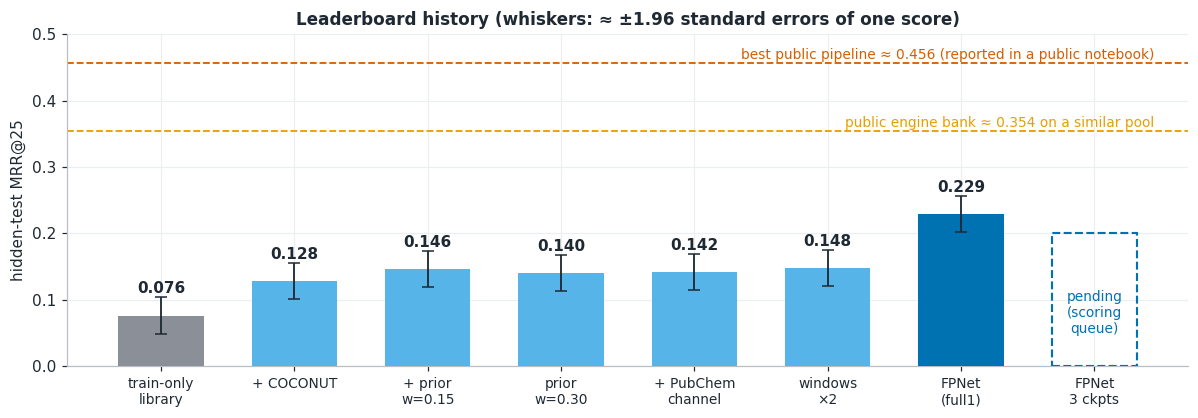

In [2]:
lb = T["leaderboard"].copy()
short = ["train-only\nlibrary", "+ COCONUT", "+ prior\nw=0.15", "prior\nw=0.30", "+ PubChem\nchannel", "windows\n×2", "FPNet\n(full1)", "FPNet\n3 ckpts"]
se = 0.28 / np.sqrt(400)
fig, ax = plt.subplots(figsize=(11, 3.9))
cols = [C["grey"], C["sky"], C["sky"], C["sky"], C["sky"], C["sky"], C["blue"], "white"]
x = np.arange(len(lb)); sc = lb.score.fillna(0).values
ax.bar(x[lb.score.notna()], sc[lb.score.notna()], color=np.array(cols, dtype=object)[lb.score.notna().values].tolist(), width=0.64, zorder=3)
ax.bar(x[lb.score.isna()], [0.2] * int(lb.score.isna().sum()), width=0.64, zorder=3, fill=False, edgecolor=C["blue"], linestyle="--", linewidth=1.4)
for i, v in enumerate(lb.score):
    if v == v:
        ax.errorbar(i, v, yerr=1.96 * se, fmt="none", ecolor=C["ink"], capsize=4, lw=1.2, zorder=4); ax.text(i, v + 1.96 * se + 0.006, f"{v:.3f}", ha="center", fontweight="bold")
    else:
        ax.text(i, 0.05, "pending\n(scoring\nqueue)", ha="center", color=C["blue"], fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(short, fontsize=9)
ax.axhline(0.456, color=C["red"], ls="--", lw=1.2); ax.text(7.45, 0.462, "best public pipeline ≈ 0.456 (reported in a public notebook)", ha="right", color=C["red"], fontsize=9)
ax.axhline(0.354, color=C["orange"], ls="--", lw=1.2); ax.text(7.45, 0.36, "public engine bank ≈ 0.354 on a similar pool", ha="right", color=C["orange"], fontsize=9)
ax.set_ylim(0, 0.5); ax.set_ylabel("hidden-test MRR@25"); ax.set_title("Leaderboard history (whiskers: ≈ ±1.96 standard errors of one score)")
plt.tight_layout(); plt.show()

**Reading.** The three pool/prior steps of v0.2 (grey → 0.146) were worth +0.07; the next three submissions are flat or noise (0.140, 0.142, 0.148). Replacing only the *ranking model* (blue) adds **+0.081**,
larger than the COCONUT step (+0.052) and about six standard errors. The remaining distance to the public pipelines (dashed lines) is 0.12–0.23.

## 1. A probe that did not matter: are the mass windows too tight?

Every query keeps only library molecules whose exact mass falls in a **window around the precursor-derived neutral mass**. The windows were calibrated on the training spectra of the lab that produced the test
data (enveda-180): for each adduct, centre = the instrument's typical ppm offset (e.g. `[M+H]+` +2.22 ppm), half-width = max(3 ppm, 3.5 σ). Our benchmark can only measure *inside* the window, so if the hidden batch
were calibrated differently, true molecules would fall outside and score 0 whatever the ranker did, invisibly. One cheap submission tests it: **double every half-width** and see whether the score moves.

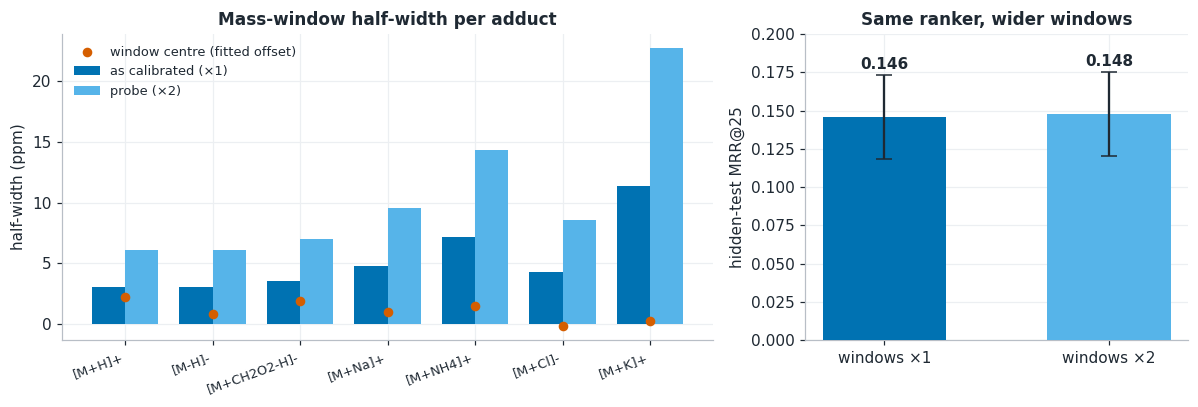

In [3]:
w = T["window"].sort_values("n", ascending=False).reset_index(drop=True)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw=dict(width_ratios=[1.7, 1]))
ax = axs[0]; xx = np.arange(len(w)); bw = 0.38
ax.bar(xx - bw / 2, w.halfwidth_x1_ppm, bw, color=C["blue"], label="as calibrated (×1)", zorder=3)
ax.bar(xx + bw / 2, w.halfwidth_x2_ppm, bw, color=C["sky"], label="probe (×2)", zorder=3)
ax.scatter(xx, w.bias_ppm, color=C["red"], zorder=5, s=28, label="window centre (fitted offset)")
ax.set_xticks(xx); ax.set_xticklabels(w.adduct, rotation=20, ha="right", fontsize=8.5); ax.set_ylabel("half-width (ppm)")
ax.set_title("Mass-window half-width per adduct"); ax.legend(fontsize=8.5)
ax = axs[1]; se = 0.28 / np.sqrt(400)
ax.bar(["windows ×1", "windows ×2"], [0.146, 0.148], color=[C["blue"], C["sky"]], width=0.55, zorder=3)
ax.errorbar([0, 1], [0.146, 0.148], yerr=1.96 * se, fmt="none", ecolor=C["ink"], capsize=5, zorder=4)
for i, v in enumerate([0.146, 0.148]): ax.text(i, v + 1.96 * se + 0.004, f"{v:.3f}", ha="center", fontweight="bold")
ax.set_ylim(0, 0.2); ax.set_ylabel("hidden-test MRR@25"); ax.set_title("Same ranker, wider windows")
plt.tight_layout(); plt.show()

**Result: 0.146 → 0.148 (+0.002, inside the noise).** If a few percent of true molecules had been cut by the windows, doubling them would have recovered those molecules at the price of extra same-mass isomers; the score would have
moved by more than a standard error. It did not, and wider windows did not cost anything measurable either. The calibration transfers to the hidden batch well enough, so **windows are not a lever** and the default stays ×1.
A probe is only worth its submission if one of its outcomes would have changed the plan; this one could have (a large gain would have redirected the day), which is why it was run, and it did not.

## 2. FPNet: a better spectrum → fingerprint model, used as a drop-in ranker

**What a "fingerprint model" does.** A *molecular fingerprint* is a long list of yes/no flags ("contains this substructure"). The strategy of this whole project is: predict the fingerprint of the unknown molecule from its
spectrum, then rank candidate molecules (same mass) by how well *their* fingerprints match the prediction. Two things decide quality: how good the prediction is, and how informative the fingerprint is.

**Ours (v0.2)** is a residual MLP over binned peaks (~32k sparse mass-defect columns), trained on 633k spectra, predicting **1,024 Morgan bits**, ranked by cosine.
**FPNet** is a public transformer by Ahmed Berat Özer: each peak is a token (m/z and neutral-loss sinusoidal embeddings + intensity), with the precursor, adduct, collision energy and polarity as a global token; it outputs **logits for 10,226 bits**
chosen from seven fingerprint families, and is trained *directly for ranking* (a contrastive loss against hard negatives of the same mass). A candidate with fingerprint **f** scores **f · logits**, which is a Bayesian log-likelihood up to a
candidate-independent constant. The checkpoint we use, `fpnet_full1`, was trained on all folds of the competition training data.

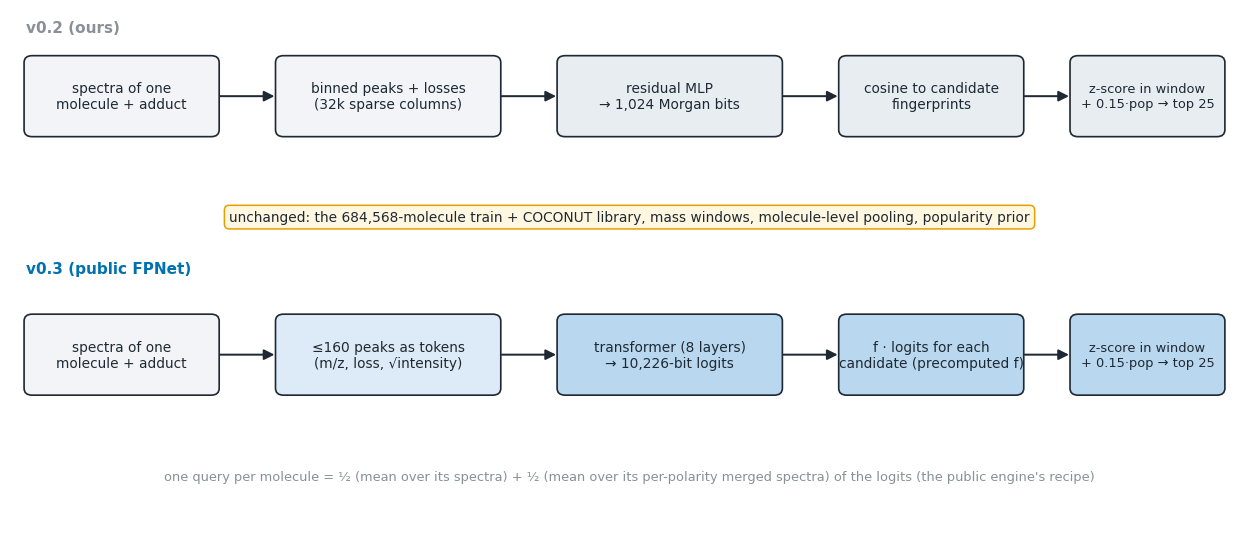

In [4]:
fig, ax = plt.subplots(figsize=(11.5, 5.0)); ax.set_xlim(-0.15, 12.1); ax.set_ylim(0, 6); ax.axis("off")
def box(x, y, w, h, text, fc, ec=C["ink"], fs=9):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08", fc=fc, ec=ec, lw=1.1)); ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs)
def arr(x0, y0, x1, y1): ax.add_patch(FancyArrowPatch((x0, y0), (x1, y1), arrowstyle="-|>", mutation_scale=14, color=C["ink"], lw=1.3))
ax.text(0.0, 5.75, "v0.2 (ours)", fontweight="bold", color=C["grey"]); ax.text(0.0, 2.95, "v0.3 (public FPNet)", fontweight="bold", color=C["blue"])
# row 1
box(0.0, 4.55, 1.9, 0.9, "spectra of one\nmolecule + adduct", "#F2F4F7"); box(2.5, 4.55, 2.2, 0.9, "binned peaks + losses\n(32k sparse columns)", "#F2F4F7"); box(5.3, 4.55, 2.2, 0.9, "residual MLP\n→ 1,024 Morgan bits", "#E8EDF2")
box(8.1, 4.55, 1.8, 0.9, "cosine to candidate\nfingerprints", "#E8EDF2"); box(10.4, 4.55, 1.5, 0.9, "z-score in window\n+ 0.15·pop → top 25", "#E8EDF2", fs=8.5)
for a, b in ((1.9, 2.5), (4.7, 5.3), (7.5, 8.1), (9.9, 10.4)): arr(a, 5.0, b, 5.0)
# row 2
box(0.0, 1.55, 1.9, 0.9, "spectra of one\nmolecule + adduct", "#F2F4F7"); box(2.5, 1.55, 2.2, 0.9, "≤160 peaks as tokens\n(m/z, loss, √intensity)", "#DCEBF7"); box(5.3, 1.55, 2.2, 0.9, "transformer (8 layers)\n→ 10,226-bit logits", "#B9D8EF")
box(8.1, 1.55, 1.8, 0.9, "f · logits for each\ncandidate (precomputed f)", "#B9D8EF"); box(10.4, 1.55, 1.5, 0.9, "z-score in window\n+ 0.15·pop → top 25", "#B9D8EF", fs=8.5)
for a, b in ((1.9, 2.5), (4.7, 5.3), (7.5, 8.1), (9.9, 10.4)): arr(a, 2.0, b, 2.0)
# shared pieces
ax.text(6.0, 3.55, "unchanged: the 684,568-molecule train + COCONUT library, mass windows, molecule-level pooling, popularity prior", ha="center", fontsize=9, color=C["ink"],
        bbox=dict(boxstyle="round,pad=0.35", fc="#FFF7E0", ec=C["orange"]))
ax.text(6.0, 0.55, "one query per molecule = ½ (mean over its spectra) + ½ (mean over its per-polarity merged spectra) of the logits (the public engine's recipe)", ha="center", fontsize=8.5, color=C["grey"])
plt.tight_layout(); plt.show()

**How it was wired in (one change).** Everything except the scoring step is untouched: same candidate library (train + COCONUT, 684,568), same mass windows, same molecule-level pooling, same popularity prior at 0.15.
The FPNet fingerprints of the candidates are precomputed in a public pool (710,701 structures, `pool_fp.npy`, packed bits), so a candidate's score is one dot product. The pool is joined to our library by
the **metric key** (tautomer-canonical InChIKey14), the library rows missing from it receive the window minimum, and within each query window the FPNet score is z-scored, the prior is added, and the top 25 are written.
A setting (`USE_FPNET`) switches the new ranker on; `FPNET_W_OURS` can blend in our MLP's cosine (not used yet, expected gain small because the MLP is the weaker ranker).

**Why a second fingerprint helps ranking.** Candidates inside one window are mostly isomers (same formula, different arrangement). A coarse 1,024-bit Morgan fingerprint separates many of them poorly; FPNet's 10,226 bits
include longer Morgan radii, feature-Morgan, path-based, atom-pair, torsion and MACCS families, and the model is trained on exactly the ranking task rather than bit-wise cross-entropy (our MLP stopped on BCE, an objective we
already found to disagree with MRR).

## 3. Checks that the wiring is correct (and why they prove nothing about the score)

Three things had to be right: (i) the candidate fingerprints must line up with our library keys, (ii) the bit layout must be the one the model was trained with, and (iii) the query recipe must match the public engine.
There is no honest *local* score for FPNet: `fpnet_full1` was trained on every molecule we could validate on. What we can do is a **leaked plumbing test**: the visible `test.parquet` is a sample of the training spectra, so the true
structure of each of its 400 molecules can be recovered from the matching training rows, and a correct pipeline must then rank it near the top — far above any real score. A near-zero number would mean a bug.

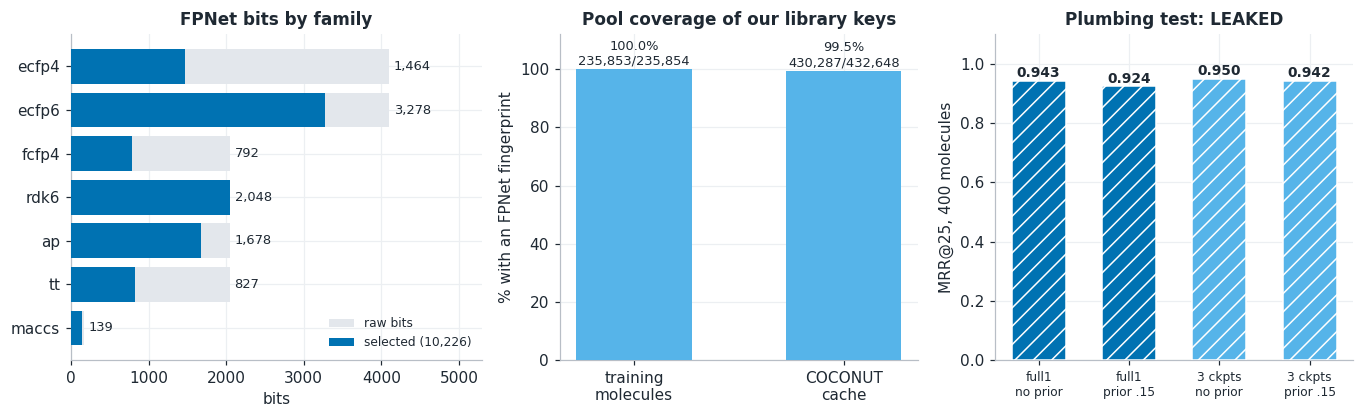

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(12.5, 3.9), gridspec_kw=dict(width_ratios=[1.15, 1.0, 1.0]))
ax = axs[0]; b = T["blocks"].iloc[::-1]
ax.barh(b.block, b.raw_bits, color="#E3E7EC", label="raw bits", zorder=2); ax.barh(b.block, b.selected_bits, color=C["blue"], label="selected (10,226)", zorder=3)
for y, (s, r) in enumerate(zip(b.selected_bits, b.raw_bits)): ax.text(r + 60, y, f"{s:,}", va="center", fontsize=8.5)
ax.set_xlim(0, 5300); ax.set_title("FPNet bits by family"); ax.legend(fontsize=8, loc="lower right"); ax.set_xlabel("bits")
ax = axs[1]; cv = T["coverage"]
frac = (cv.n_in_pool / cv.n).values
ax.bar(["training\nmolecules", "COCONUT\ncache"], frac * 100, color=[C["sky"], C["sky"]], width=0.55, zorder=3)
for i, (f, k, n) in enumerate(zip(frac, cv.n_in_pool, cv.n)): ax.text(i, f * 100 + 1.5, f"{f:.1%}\n{k:,}/{n:,}", ha="center", fontsize=8.5)
ax.set_ylim(0, 112); ax.set_ylabel("% with an FPNet fingerprint"); ax.set_title("Pool coverage of our library keys")
ax = axs[2]; p = T["plumbing"]
lab = ["full1\nno prior", "full1\nprior .15", "3 ckpts\nno prior", "3 ckpts\nprior .15"]
ax.bar(lab, p.mrr25_leaked, color=[C["blue"], C["blue"], C["sky"], C["sky"]], width=0.6, zorder=3, hatch="//", edgecolor="white")
for i, v in enumerate(p.mrr25_leaked): ax.text(i, v + 0.012, f"{v:.3f}", ha="center", fontsize=9, fontweight="bold")
ax.set_ylim(0, 1.1); ax.set_title("Plumbing test: LEAKED"); ax.set_ylabel("MRR@25, 400 molecules"); ax.tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()

**Reading the figure.** *Left:* the selected bits are dominated by Morgan radius-3 (3,278), atom-pair, torsion and the full path fingerprint (all 2,048 RDKit bits); only 1,464 of the 4,096 radius-2 Morgan bits were kept — this is a
richer description of a candidate than our 1,024 bits. *Middle:* 99.5–100% of our library keys have a precomputed fingerprint (the training keys 235,853 of 235,854; the COCONUT cache 430,287 of 432,648), so the join loses almost nothing.
*Right (hatched = leaked):* on the 400 visible-test molecules the pipeline ranks the recovered truth at or near the top for almost all of them (MRR@25 0.92–0.95), the median window holds 54 candidates and no library row lacks a
fingerprint. This only shows that queries, bit layout, key join, windows and ranking are wired correctly; **it is not an estimate of the real score**, which is the 0.229 above.

**What 0.229 does and does not say.** It is one submission (standard error ≈ 0.014), so the +0.081 over 0.148 is solid, but we have not separated FPNet's contribution from the popularity prior's (kept at 0.15, a value chosen when ranking with the
MLP's scores), and the distance to the public full pipelines (0.35–0.46) means FPNet scoring alone is not the whole story.

**v0.3c (pending).** The same notebook with the logits of three FPNet checkpoints averaged (`fpnet_full1` plus the public `fpnet_0` and `fpnet_1`; identical architecture and bit layout). Pre-registered expectation, written *before* the result:
**+0.00 to +0.03**, because in the public notebooks' own version history swapping one FPNet checkpoint for another changed the score by only 0.002 (0.380 → 0.378). Kaggle's scoring queue for this competition was reported to take up to 24 h, so
the result is not in this release; see `docs/EXPERIMENT_LOG.md` and `docs/PLAN_2026-10-23.md` (in the working repository) for when it lands.

## 4. Limitations and what is next

| # | Limitation | Consequence |
|---|---|---|
| 1 | **No local validation of FPNet.** `fpnet_full1` saw all training molecules; the fold-safe FPNet checkpoints (trained without identity folds and the public natural-product panel) are the way to measure unseen-molecule behaviour, but their folds do not match our scaffold split. | The leaderboard is the only arbiter; one score has standard error ≈ 0.014. |
| 2 | **Effects not separated.** The gain mixes FPNet's better fingerprint, its ranking-aware training and the interaction with our unchanged popularity weight. | We cannot say how much a retuned prior or a blend with our MLP would add; both are small expected changes. |
| 3 | **The candidate pool still limits the score.** Only an estimated 25–33% of hidden molecules are in train + COCONUT; the PubChem channel (kept implemented, off) was neutral with the weaker ranker. | Reconsider the channel only with a stronger ranker. |
| 4 | **Public datasets, non-commercial licence.** The FPNet checkpoint, code and pool carry the competition-data terms (non-commercial, attribution). | Keep the project non-commercial; credit the authors (section 5); do not redistribute the weights. |
| 5 | **Scoring queue.** The ensemble submission (v0.3c) is pending. | Its entry in the tables is a blank, not a zero. |
| 6 | Everything listed in v0.2 still applies (placeholder visible test, mass-window calibration from one lab, one seed per run, 633k of 1.73M spectra used, ...). | See the v0.2 report. |

**Next (not done yet).** The public stack that reaches 0.35–0.46 adds, on top of FPNet scoring: analog propagation (mass-shifted similarity to training spectra, propagated through structural similarity), fragmentation and sub-formula
explanations of peaks, generated derivatives of close analogues, and a trained LightGBM ranker over those features. Its code is public; the next step is a feasibility study of running that engine (inputs, runtime, licence), and only then
the build. Other candidates: fold-safe FPNet checkpoints in the ensemble, and a small fusion weight for our MLP.

## 5. Credits and licences

* **FPNet architecture, fingerprint bit selection, candidate pool and the checkpoints used:** Ahmed Berat Özer — Kaggle datasets `ahmedberatozer/casmi26-fpnet-full1`, `casmi26-v3-models`, `casmi26-v2-pool` (https://www.kaggle.com/ahmedberatozer).
  **Fold-safe training kit and audit:** Dmitrii Gluzdov — `dmitriigluzdov/casmi26-fold-safe-fpnet`; **popularity prior:** `dmitriigluzdov/casmi26-pubchem-popularity-prior`. These files carry the competition data terms
  (non-commercial, attribution); this repository contains none of the model weights, fingerprints or competition data, only code that loads them from Kaggle datasets.
* COCONUT structures come from the public Kaggle dataset `prvsiyan/coconut-casmi26-candidates` (CC BY-NC-SA 4.0). Competition data: Enveda CASMI 2026 on Kaggle (reported CC BY-NC 4.0). Comparisons with public pipelines are quoted
  from the public notebook *CASMI 26: The Data Behind Spectra to Structures*.
* The code-sharing clause of the competition rules (sections 4/6) has not been read in full by the author; check it before making this repository public while the competition is running (final submission 2026-12-14).